# Pittsburgh Penguins: player impact with MoneyPuck

This notebook downloads one season of Pittsburgh skater summaries, shows the original rows, makes a smaller player table, checks the values, and draws one chart. It is written for someone new to data work: read the plain English note before each code cell, then run that cell with **Shift+Enter**.

**Source and use:** MoneyPuck's [official download page](https://www.moneypuck.com/data.htm) lists season summary CSV files. This notebook uses the Pittsburgh skater file for the **2025–26 regular season**. MoneyPuck says the listed data is free for non-commercial use and asks that it be credited whenever shown; please keep this credit if you share the table or chart. The file is already in `data/`, so the notebook works offline; set `REFRESH_DATA = True` in the download cell to get the latest copy from MoneyPuck.

**What “impact” means here:** on-ice expected-goal share estimates how much of the expected goal chance total belonged to Pittsburgh while that player was on the ice. Above 50% means Pittsburgh had more expected goals than its opponents in those minutes. This is a useful snapshot, not proof that a player alone caused the result.

## 1. Get the source data

The official file is a CSV, which is a plain text table. The address below is the public file linked from MoneyPuck's season data. We keep a copy in the project so you can repeat the rest of the notebook without internet access. The optional refresh setting replaces it with MoneyPuck's current version.

In [1]:
from pathlib import Path
import urllib.request
import pandas as pd
import matplotlib.pyplot as plt

SOURCE_URL = 'https://moneypuck.com/moneypuck/playerData/seasonSummary/2025/regular/teams/skaters/PIT.csv'
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / 'data').exists():  # Also works when Jupyter starts in the notebooks folder.
    PROJECT_DIR = PROJECT_DIR.parent
DATA_FILE = PROJECT_DIR / 'data' / 'moneypuck_pit_2025_26_skaters_raw.csv'
REFRESH_DATA = False  # Change to True when you want to download a fresh copy.

if REFRESH_DATA or not DATA_FILE.exists():
    DATA_FILE.parent.mkdir(parents=True, exist_ok=True)
    request = urllib.request.Request(SOURCE_URL, headers={'User-Agent': 'Penguins analytics learning notebook'})
    with urllib.request.urlopen(request, timeout=30) as response:
        DATA_FILE.write_bytes(response.read())
    print('Downloaded the listed MoneyPuck file to', DATA_FILE)
else:
    print('Using the MoneyPuck CSV saved in this project:', DATA_FILE)

raw = pd.read_csv(DATA_FILE)
print(f'Raw data: {raw.shape[0]} rows and {raw.shape[1]} columns')

Using the MoneyPuck CSV saved in this project: C:\Users\ttusk\VSCodePSU\pitpensdashboard\pittsburgh-penguins-dashboard\data\moneypuck_pit_2025_26_skaters_raw.csv
Raw data: 190 rows and 154 columns


## 2. Look at the raw data

The raw table has one row for a player **and a game situation**. For example, the same player can have separate rows for all situations, 5-on-5, power play, and penalty kill. The columns include player details, time on ice, team shot and expected-goal shares, and individual events. The next cell shows the actual first rows and a small selection of columns so the structure is visible without flooding the screen with all 154 columns.

In [2]:
print('All column names (first 30 shown):')
print(', '.join(raw.columns[:30]))
print('\nSituation values (different kinds of ice time):')
print(', '.join(sorted(raw['situation'].dropna().unique())))
print('\nRaw sample: first 8 rows and 10 useful columns')
raw[['name', 'team', 'position', 'situation', 'games_played', 'icetime',
     'onIce_xGoalsPercentage', 'onIce_corsiPercentage', 'I_F_xGoals', 'I_F_goals']].head(8)

All column names (first 30 shown):
playerId, season, name, team, position, situation, games_played, icetime, shifts, gameScore, onIce_xGoalsPercentage, offIce_xGoalsPercentage, onIce_corsiPercentage, offIce_corsiPercentage, onIce_fenwickPercentage, offIce_fenwickPercentage, iceTimeRank, I_F_xOnGoal, I_F_xGoals, I_F_xRebounds, I_F_xFreeze, I_F_xPlayStopped, I_F_xPlayContinuedInZone, I_F_xPlayContinuedOutsideZone, I_F_flurryAdjustedxGoals, I_F_scoreVenueAdjustedxGoals, I_F_flurryScoreVenueAdjustedxGoals, I_F_primaryAssists, I_F_secondaryAssists, I_F_shotsOnGoal

Situation values (different kinds of ice time):
4on5, 5on4, 5on5, all, other

Raw sample: first 8 rows and 10 useful columns


,name,team,position,situation,games_played,icetime,onIce_xGoalsPercentage,onIce_corsiPercentage,I_F_xGoals,I_F_goals
0,Kevin Hayes,PIT,R,other,28,287.0,0.05,0.43,0.00,0.0
1,Kevin Hayes,PIT,R,all,28,20956.0,0.54,0.54,4.20,4.0
2,Kevin Hayes,PIT,R,5on5,28,18841.0,0.55,0.52,3.94,4.0
3,Kevin Hayes,PIT,R,4on5,28,2.0,0.00,0.00,0.00,0.0
4,Kevin Hayes,PIT,R,5on4,28,1826.0,0.72,0.76,0.25,0.0
5,Sam Poulin,PIT,R,other,2,0.0,0.00,0.00,0.00,0.0
6,Sam Poulin,PIT,R,all,2,1658.0,0.51,0.51,0.21,0.0
7,Sam Poulin,PIT,R,5on5,2,1589.0,0.52,0.54,0.21,0.0


## 3. Make a simple player table

To avoid counting a player several times, keep only `all` situations. We also use a 10 game minimum so a very short appearance does not dominate the comparison. The columns below have friendlier names: ice time is converted from seconds to minutes, and the two shares are displayed as percentages. `Expected goals` estimates the quality of a player's shots; `Actual goals` is the goals they scored.

In [3]:
all_situations = raw.loc[raw['situation'].eq('all')].copy()
all_situations['games_played'] = pd.to_numeric(all_situations['games_played'], errors='coerce')
all_situations = all_situations.loc[all_situations['games_played'].ge(10)].copy()

players = pd.DataFrame({
    'Player': all_situations['name'].str.strip(),
    'Pos': all_situations['position'],
    'Games': all_situations['games_played'].astype(int),
    'Ice time (min)': pd.to_numeric(all_situations['icetime']) / 60,
    'On-ice xG share (%)': pd.to_numeric(all_situations['onIce_xGoalsPercentage']) * 100,
    'On-ice shot attempt share (%)': pd.to_numeric(all_situations['onIce_corsiPercentage']) * 100,
    'Expected goals': pd.to_numeric(all_situations['I_F_xGoals']),
    'Actual goals': pd.to_numeric(all_situations['I_F_goals']),
    'player_id': all_situations['playerId'],
})
players = players.sort_values('On-ice xG share (%)', ascending=False).reset_index(drop=True)
players['Ice time (min)'] = players['Ice time (min)'].round(1)
players['On-ice xG share (%)'] = players['On-ice xG share (%)'].round(1)
players['On-ice shot attempt share (%)'] = players['On-ice shot attempt share (%)'].round(1)
players['Expected goals'] = players['Expected goals'].round(1)
players = players.drop(columns='player_id')
players.to_csv(PROJECT_DIR / 'data' / 'penguins_player_impact_2025_26.csv', index=False)
print('Saved the clean player table to data/penguins_player_impact_2025_26.csv')
players

Saved the clean player table to data/penguins_player_impact_2025_26.csv


,Player,Pos,Games,Ice time (min),On-ice xG share (%),On-ice shot attempt share (%),Expected goals,Actual goals
0,Evgeni Malkin,C,56,985.2,61.0,57.0,18.6,19.0
1,Ilya Solovyov,D,30,382.4,58.0,54.0,0.9,1.0
2,Ville Koivunen,R,39,496.8,57.0,59.0,5.0,2.0
3,Tommy Novak,C,82,1171.1,57.0,53.0,17.3,16.0
4,Sidney Crosby,C,68,1307.7,57.0,57.0,21.4,29.0
5,Ben Kindel,C,77,1159.9,56.0,55.0,21.7,17.0
6,Anthony Mantha,R,81,1230.2,56.0,55.0,18.3,33.0
7,Bryan Rust,R,72,1436.0,55.0,53.0,29.0,29.0
8,Erik Karlsson,D,75,1770.0,55.0,56.0,11.4,15.0
9,Kevin Hayes,R,28,349.3,54.0,54.0,4.2,4.0


## 4. Check that the numbers look right

These checks answer practical questions: did we end up with one row per player, are percentages between 0% and 100%, are there missing values, and did the game filter work? A 50% share is even expected goals or shot attempts; values above or below it are plausible because players have different roles and teammates.

In [4]:
checks = {
    'Rows in raw file': len(raw),
    'Columns in raw file': len(raw.columns),
    'Rows after all-situations and 10-game filter': len(players),
    'Player names are unique': bool(players['Player'].is_unique),
    'No missing values in the clean table': bool(not players.isna().any().any()),
    'xG share stays from 0% to 100%': bool(players['On-ice xG share (%)'].between(0, 100).all()),
    'Shot attempt share stays from 0% to 100%': bool(players['On-ice shot attempt share (%)'].between(0, 100).all()),
    'Every player reached 10 games': bool(players['Games'].ge(10).all()),
}
for check, result in checks.items():
    print(f'{check}: {result}')

assert all(bool(value) for value in list(checks.values())[3:]), 'A data check failed; inspect the rows before interpreting the chart.'

Rows in raw file: 190
Columns in raw file: 154
Rows after all-situations and 10-game filter: 29
Player names are unique: True
No missing values in the clean table: True
xG share stays from 0% to 100%: True
Shot attempt share stays from 0% to 100%: True
Every player reached 10 games: True


## 5. Chart player on-ice expected-goal share

Each bar compares expected goals for Pittsburgh with expected goals for opponents during that player's ice time. The 50% line means an even share. This chart uses the same 10-game minimum as the table and orders players from highest to lowest share.

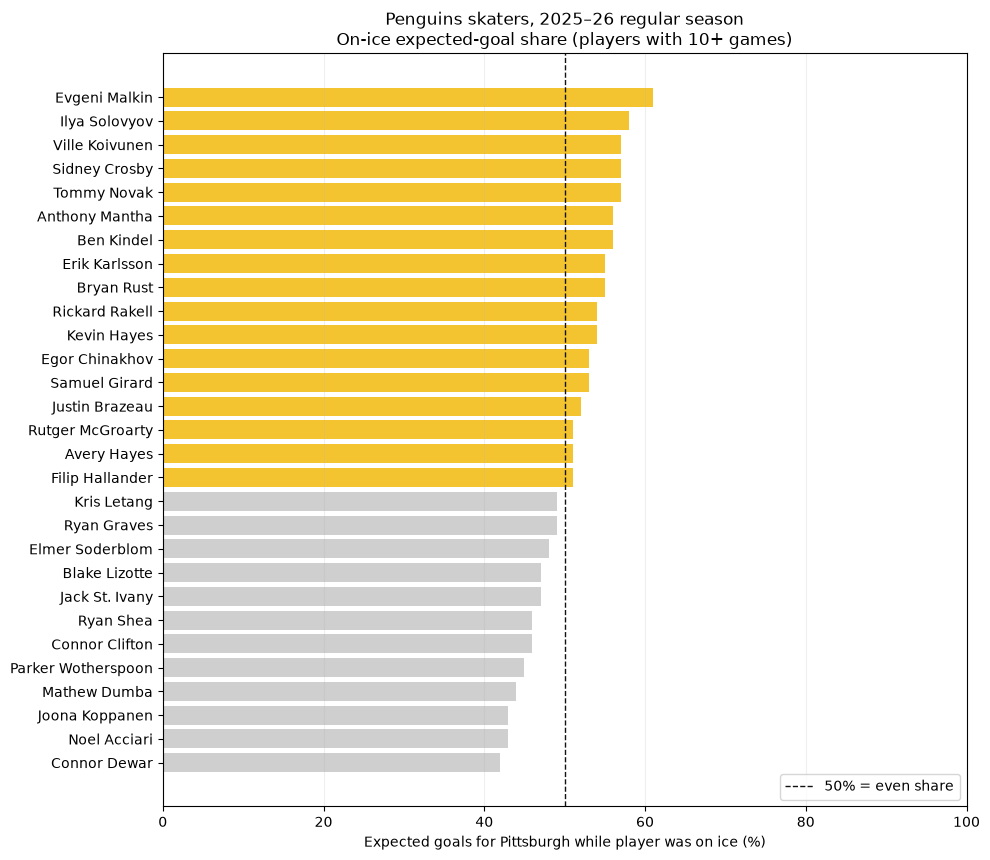

In [5]:
chart = players.sort_values('On-ice xG share (%)', ascending=True)
colors = ['#cfcfcf' if value < 50 else '#f4c430' for value in chart['On-ice xG share (%)']]
fig, ax = plt.subplots(figsize=(10, max(7, len(chart) * 0.30)))
ax.barh(chart['Player'], chart['On-ice xG share (%)'], color=colors)
ax.axvline(50, color='#111111', linestyle='--', linewidth=1, label='50% = even share')
ax.set_xlim(0, 100)
ax.set_xlabel('Expected goals for Pittsburgh while player was on ice (%)')
ax.set_title('Penguins skaters, 2025–26 regular season\nOn-ice expected-goal share (players with 10+ games)')
ax.legend(loc='lower right')
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
fig.savefig(PROJECT_DIR / 'data' / 'penguins_impact_chart_2025_26.png', dpi=160, bbox_inches='tight')
plt.show()

## 6. Short summary

MoneyPuck provides downloadable CSV summaries. We loaded Pittsburgh's 2025–26 regular season skater file, saw that rows are split by situation, kept each player's `all` row, and required at least 10 games. We converted ice time and percentages into familiar units, checked for duplicate players, missing data, and impossible percentages, then charted each player's expected-goal share against the 50% even mark.

A higher bar means Pittsburgh generated a larger share of expected goals while that skater was on the ice. It is one view of general on-ice impact; playing time, teammates, opponents, role, and luck also affect the numbers.